In [15]:
!pip install wfdb tensorflow scikit-learn scipy matplotlib seaborn

In [16]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [17]:
DATA_DIR = "mitdb"

os.makedirs(DATA_DIR, exist_ok=True)

wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

print("Database downloaded successfully.")

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [18]:
records = [
    "100", "101", "102", "103", "104", "105",
    "106", "107", "108", "109", "111", "112",
    "113", "114", "115", "116", "117", "118",
    "119", "121", "122", "123", "124", "200",
    "201", "202", "203", "205", "207", "208",
    "209", "210", "212", "213", "214", "215",
    "217", "219", "220", "221", "222", "223",
    "228", "230", "231", "232", "233", "234"
]

paced_records = {"102", "104", "107", "217"}

records = [
    record for record in records
    if record not in paced_records
]

# AAMI heartbeat classes
CLASS_NAMES = ["N", "S", "V", "F", "Q"]

class_map = {
    # N: Normal
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",

    # S: Supraventricular ectopic
    "A": "S", "a": "S", "J": "S", "S": "S",

    # V: Ventricular ectopic
    "V": "V", "E": "V",

    # F: Fusion
    "F": "F",

    # Q: Unknown / paced
    "/": "Q", "f": "Q", "Q": "Q"
}

label_to_int = {
    label: index for index, label in enumerate(CLASS_NAMES)
}

print("Number of records:", len(records))
print("Classes:", CLASS_NAMES)

Number of records: 44
Classes: ['N', 'S', 'V', 'F', 'Q']


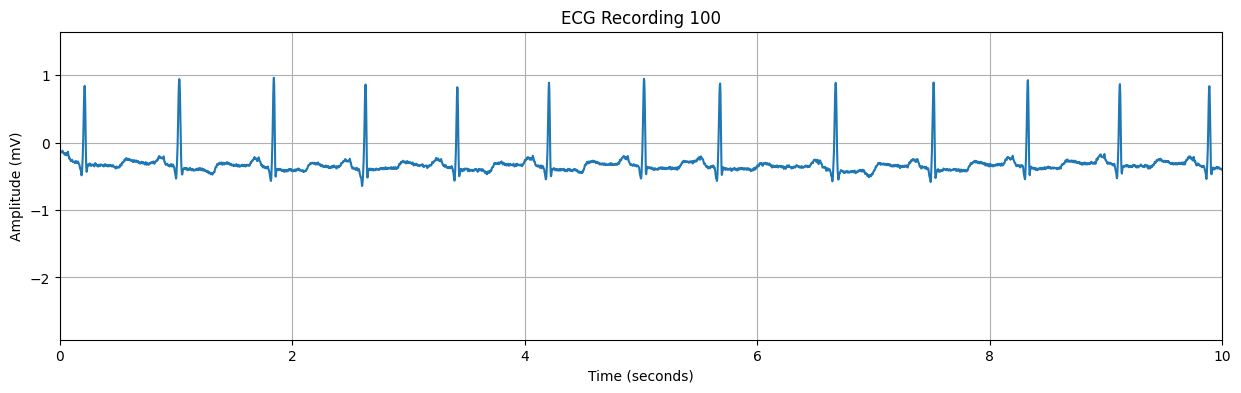

Sampling rate: 360 Hz
Signal shape: (650000, 2)


In [19]:
record_name = "100"

record = wfdb.rdrecord(
    os.path.join(DATA_DIR, record_name)
)

signal = record.p_signal
sampling_rate = record.fs

time = np.arange(len(signal)) / sampling_rate

plt.figure(figsize=(15, 4))
plt.plot(time, signal[:, 0])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title(f"ECG Recording {record_name}")
plt.xlim(0, 10)
plt.grid()
plt.show()

print("Sampling rate:", sampling_rate, "Hz")
print("Signal shape:", signal.shape)

In [20]:
FS = 360

BEFORE = int(0.2 * FS)
AFTER = int(0.4 * FS)

WINDOW_SIZE = BEFORE + AFTER

def bandpass_filter(signal, fs=360):
    """
    Remove baseline wander and high-frequency noise.
    """
    sos = butter(
        4,
        [0.5, 40],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return sosfiltfilt(sos, signal)


def normalize_beat(beat):
    """
    Normalize each heartbeat independently.
    """
    mean = np.mean(beat)
    std = np.std(beat)

    if std < 1e-8:
        return beat - mean

    return (beat - mean) / std


def extract_beats(record_name):
    """
    Read, filter, and segment a record.
    Returns heartbeat segments and AAMI labels.
    """

    record_path = os.path.join(DATA_DIR, record_name)

    record = wfdb.rdrecord(record_path)
    annotation = wfdb.rdann(record_path, "atr")

    signal = record.p_signal[:, 0]

    filtered_signal = bandpass_filter(
        signal,
        fs=record.fs
    )

    beats = []
    labels = []

    for sample, symbol in zip(
        annotation.sample,
        annotation.symbol
    ):

        # Skip annotations that are not mapped to AAMI classes
        if symbol not in class_map:
            continue

        start = sample - BEFORE
        end = sample + AFTER

        # Skip beats near recording boundaries
        if start < 0 or end > len(filtered_signal):
            continue

        beat = filtered_signal[start:end]

        if len(beat) != WINDOW_SIZE:
            continue

        beat = normalize_beat(beat)

        beats.append(beat)
        labels.append(class_map[symbol])

    return np.array(beats), np.array(labels)

In [21]:
X_all = []
y_all = []
groups = []

for record_name in records:

    try:
        beats, labels = extract_beats(record_name)

        if len(beats) == 0:
            continue

        X_all.append(beats)
        y_all.append(labels)

        # Record ID used for patient-independent splitting
        groups.extend([record_name] * len(labels))

        print(
            f"Record {record_name}: "
            f"{len(beats)} beats extracted"
        )

    except Exception as error:
        print(f"Error processing {record_name}: {error}")


X_all = np.concatenate(X_all, axis=0)
y_all = np.concatenate(y_all, axis=0)
groups = np.array(groups)

# Convert class labels into integers
y_all = np.array([
    label_to_int[label] for label in y_all
])

# RNN input shape: (samples, timesteps, features)
X_all = X_all[..., np.newaxis]

print("\nDataset shape:", X_all.shape)
print("Labels shape:", y_all.shape)

Record 100: 2272 beats extracted
Record 101: 1865 beats extracted
Record 103: 2083 beats extracted
Record 105: 2572 beats extracted
Record 106: 2027 beats extracted
Record 108: 1763 beats extracted
Record 109: 2531 beats extracted
Record 111: 2124 beats extracted
Record 112: 2538 beats extracted
Record 113: 1794 beats extracted
Record 114: 1879 beats extracted
Record 115: 1952 beats extracted
Record 116: 2411 beats extracted
Record 117: 1534 beats extracted
Record 118: 2277 beats extracted
Record 119: 1987 beats extracted
Record 121: 1862 beats extracted
Record 122: 2475 beats extracted
Record 123: 1517 beats extracted
Record 124: 1618 beats extracted
Record 200: 2600 beats extracted
Record 201: 1963 beats extracted
Record 202: 2135 beats extracted
Record 203: 2980 beats extracted
Record 205: 2655 beats extracted
Record 207: 1859 beats extracted
Record 208: 2953 beats extracted
Record 209: 3004 beats extracted
Record 210: 2648 beats extracted
Record 212: 2747 beats extracted
Record 213

  Class  Count
0     N  90094
1     S   2781
2     V   7008
3     F    802
4     Q     15


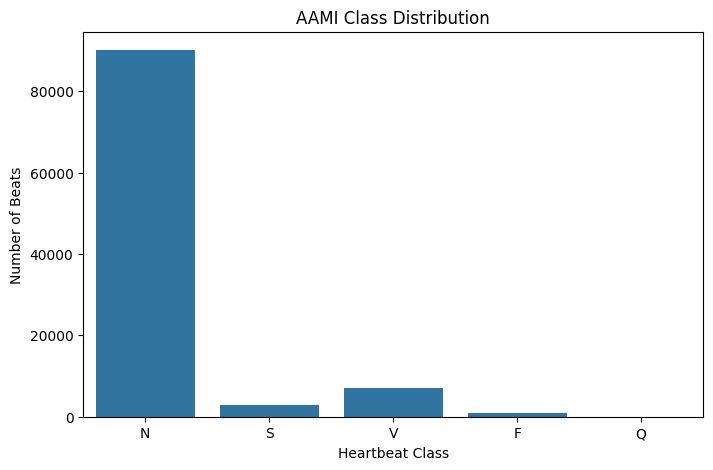

In [22]:
class_counts = pd.Series(
    y_all
).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Count": [
        class_counts.get(i, 0)
        for i in range(len(CLASS_NAMES))
    ]
})

print(class_distribution)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Count"
)

plt.title("AAMI Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")
plt.show()

In [23]:
unique_records = np.unique(groups)

# 70% training, 30% temporary
train_records, temp_records = train_test_split(
    unique_records,
    test_size=0.30,
    random_state=SEED
)

# 15% validation, 15% test
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.50,
    random_state=SEED
)


train_mask = np.isin(groups, train_records)
val_mask = np.isin(groups, val_records)
test_mask = np.isin(groups, test_records)

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]


print("Training records:", train_records)
print("Validation records:", val_records)
print("Test records:", test_records)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Training records: ['122' '117' '232' '119' '113' '121' '213' '208' '100' '212' '233' '108'
 '115' '215' '101' '230' '201' '103' '219' '203' '221' '114' '202' '123'
 '234' '200' '111' '118' '210' '228']
Validation records: ['205' '124' '220' '116' '109' '222' '106']
Test records: ['105' '209' '223' '214' '231' '112' '207']

Training shape: (68522, 216, 1)
Validation shape: (15770, 216, 1)
Test shape: (16408, 216, 1)


In [24]:
classes_present = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes_present, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.2260407732400871, 1: 7.301225359616409, 2: 2.615343511450382, 3: 17.82106631989597, 4: 1713.05}


In [25]:
def build_model(model_type):

    model = Sequential()

    if model_type == "RNN":
        model.add(
            SimpleRNN(
                64,
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    elif model_type == "LSTM":
        model.add(
            LSTM(
                64,
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    elif model_type == "GRU":
        model.add(
            GRU(
                64,
                input_shape=(WINDOW_SIZE, 1)
            )
        )

    model.add(Dropout(0.3))

    model.add(
        Dense(
            len(CLASS_NAMES),
            activation="softmax"
        )
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [26]:
EPOCHS = 30
BATCH_SIZE = 128

model_types = ["RNN", "LSTM", "GRU"]

models = {}
histories = {}
results = {}

for model_type in model_types:

    print(f"\nTraining {model_type} model...")

    model = build_model(model_type)

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[early_stopping],
        verbose=1
    )

    models[model_type] = model
    histories[model_type] = history

    results[model_type] = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    print(
        f"{model_type} Test Loss: {results[model_type][0]:.4f}"
    )

    print(
        f"{model_type} Test Accuracy: "
        f"{results[model_type][1]:.4f}"
    )


Training RNN model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.2279 - loss: 1.5221 - val_accuracy: 0.3813 - val_loss: 1.3580
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.2394 - loss: 1.5427 - val_accuracy: 0.4031 - val_loss: 1.4209
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.2584 - loss: 1.5609 - val_accuracy: 0.4774 - val_loss: 1.4325
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.2000 - loss: 1.5935 - val_accuracy: 0.0887 - val_loss: 1.5583
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.1962 - loss: 1.4958 - val_accuracy: 0.0091 - val_loss: 1.5688
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.1984 - loss: 1.4883 - val_accuracy: 0.2323 - val_loss: 1.4939
RNN Test Loss: 1.5715
RNN Test Accuracy: 0.1136

Training LSTM model...
Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.2356 - loss: 1.7348 - val_accuracy: 0.0148 - val_loss: 1.5271
Epoch 2/30
536/536

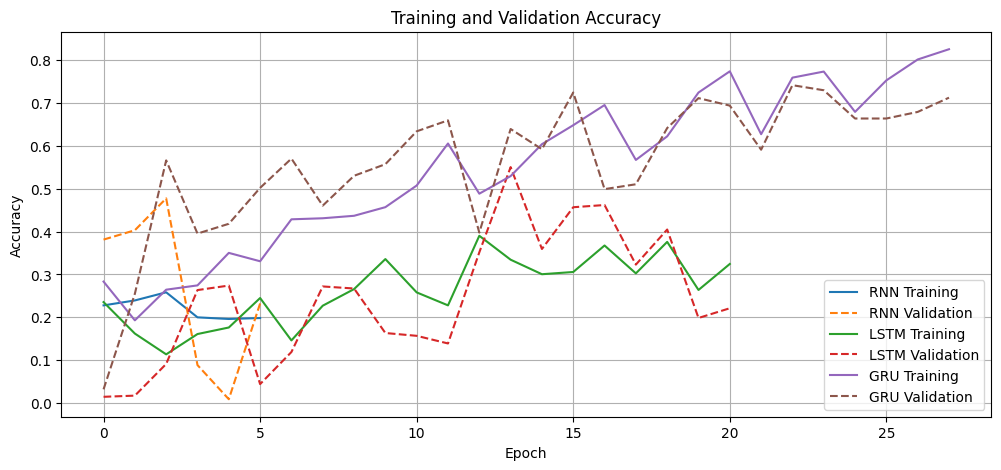

In [27]:
plt.figure(figsize=(12, 5))

for model_type in model_types:

    history = histories[model_type]

    plt.plot(
        history.history["accuracy"],
        label=f"{model_type} Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=f"{model_type} Validation"
    )

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

In [28]:
evaluation_results = []

for model_type in model_types:

    model = models[model_type]

    y_pred_prob = model.predict(
        X_test,
        verbose=0
    )

    y_pred = np.argmax(
        y_pred_prob,
        axis=1
    )

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    evaluation_results.append({
        "Model": model_type,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"\n{model_type} Classification Report")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(CLASS_NAMES)),
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )


results_df = pd.DataFrame(evaluation_results)

print("\nModel Comparison")
print(
    results_df.round(4).to_string(index=False)
)


RNN Classification Report
              precision    recall  f1-score   support

           N       0.92      0.11      0.20     14837
           S       0.15      0.35      0.21       566
           V       0.01      0.00      0.00       983
           F       0.00      0.93      0.00        15
           Q       0.00      0.14      0.00         7

    accuracy                           0.11     16408
   macro avg       0.22      0.31      0.08     16408
weighted avg       0.84      0.11      0.19     16408


LSTM Classification Report
              precision    recall  f1-score   support

           N       0.93      0.24      0.39     14837
           S       0.09      0.13      0.10       566
           V       0.09      0.33      0.14       983
           F       0.00      0.33      0.01        15
           Q       0.00      0.14      0.00         7

    accuracy                           0.25     16408
   macro avg       0.22      0.24      0.13     16408
weighted avg       0.8

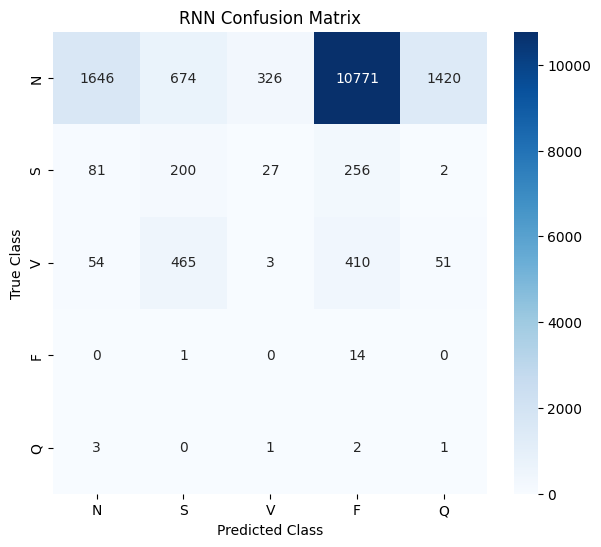

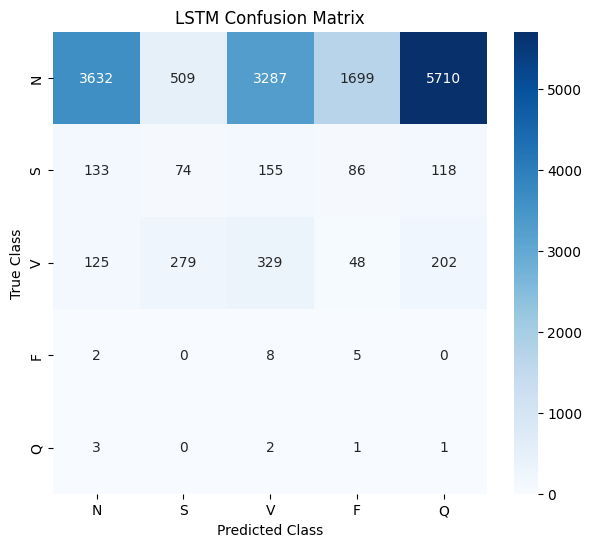

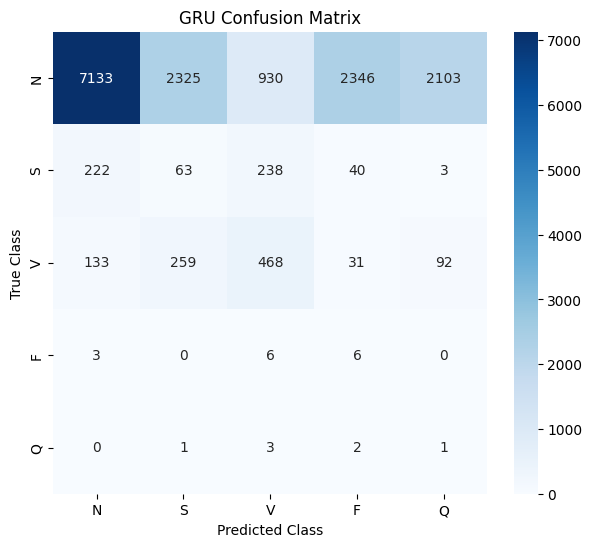

In [29]:
for model_type in model_types:

    y_pred = np.argmax(
        models[model_type].predict(
            X_test,
            verbose=0
        ),
        axis=1
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(CLASS_NAMES))
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"{model_type} Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.show()

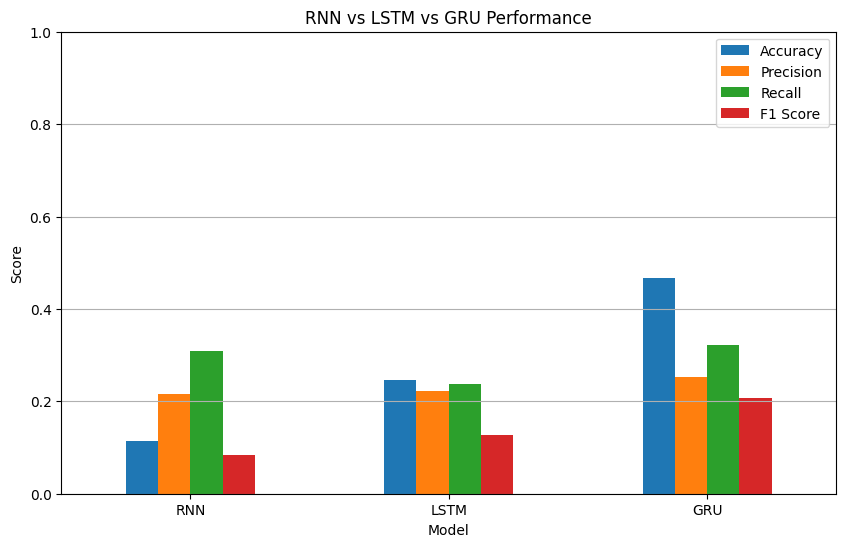

In [30]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()